### Overview: Pajaro Pysheds Hillslope and ReNeM Prototype

This notebook demonstrates a lightweight, open-source workflow to support the Recharge Net Metering (ReNeM) program by linking DEM-based hillslope hydrology to a site-specific runoff and rebate calculation.

We use the operational **Bokariza–Drobac MAR basin** as our case study to compare Python-derived catchment area and runoff behavior against published values from the UC Santa Cruz Hydrogeology Group, serving as a check on model realism.

The workflow is organized into six consecutive steps:

1. **Load and Verify Base DEM**  
   We started from a raw USGS 1/3 arc-second DEM file (EPSG:4269) and first loaded it into QGIS and used the **Warp (Reproject)** tool to convert the grid into the local metric coordinate system, **UTM Zone 10N (EPSG:26910)**. This conversion allows hydrologic routing using horizontal (X, Y) and vertical (Z) dimensions sharing the same unit (meters) to calculate accurate slopes and flow paths. During this warp step, we also standardized the pixel size to exactly 10 meters and assigned a designated NoData value of **`-9999`** to any empty edge pixels. The resulting projected file (`pajaro_valley_utm10n.tif`) is loaded here using `rioxarray` to preserve these spatial properties.

2. **Spatial Cropping and Standardization**  
   To prevent memory errors and keep computations fast in Google Colab, the reprojected regional DEM is clipped to a tight bounding box around the Pajaro Valley Basin (PVGB) and saved as a lightweight, local raster named `pajaro_only_dem.tif`.

3. **Hydrologic Conditioning and Routing (pysheds)**  
   The cropped DEM is ingested into a `pysheds.Grid`. Standard hydrologic pre-processing is applied: single-cell pits and multi-cell depressions are filled, and flat areas are resolved to enforce a continuous downslope gradient. Using a D8 routing scheme, flow directions and accumulation are computed and plotted on a log-scale to reveal the natural drainage network.

4. **Real-World Catchment Delineation (Bokariza–Drobac)**  
   The physical coordinates of the Bokariza–Drobac MAR basin are converted to UTM Zone 10N and snapped to the nearest active drainage channel using `grid.snap_to_mask(acc > 500, …)`. From this snapped outlet, `pysheds` delineates the contributing hillslope catchment. The total drainage acreage is calculated directly from the boolean mask (≈149.4 acres) and validated against the published area (≈172 acres) from the UCSC study.

5. **Event-Based and Annual Runoff Estimation (SCS-CN)**  
   Within the catchment, we generate an elevation-partitioned Curve Number (CN) grid. Lower agricultural flat margins (< 35m elevation) are assigned a CN of ~80, while the upper native sandy hillslope (>= 35m elevation) is assigned a CN of ~60. We model a 2.5-inch design storm to estimate peak runoff, and calculate the total annual surface runoff generated across a median 22-inch water year. *(Note: The annual runoff is a lumped-event approximation and represents the upper-bound limit of available surface water).*

6. **Site-Specific ReNeM Rebate Evaluation**  
   We implement a dynamic ReNeM rebate calculation. Rather than using an arbitrary placeholder, we apply a **System Capture & Infiltration Efficiency Factor ($\eta = 45\%$)** to our modeled annual runoff to estimate the volume of water actually recharged. We subtract a 10% baseline for natural incidental infiltration and multiply the net benefit by 50% of the local PV Water groundwater pumping fee ($346/AF) to calculate the estimated annual rebate for the landowner.

In [ ]:
# ==============================================================================
# Step 1a: Environment Setup
# ==============================================================================
!pip install -q pysheds rioxarray matplotlib numpy pandas pyproj
print("Libraries installed successfully.")

## 📊 Data Sourcing & Preparation

* **Base Elevation Data:** Downloaded as raw USGS 1/3 arc-second DEM tiles from the USGS 3DEP National Map.
* **Preprocessing (QGIS):**
  1. Reprojected/Warped from geographic coordinates (EPSG:4269) to local metric grid **UTM Zone 10N (EPSG:26910)**[cite: 11].
  2. Standardized pixel resolution to 10 meters[cite: 11].
  3. Assigned NoData values to empty edge pixels and saved as `pajaro_valley_utm10n.tif`[cite: 11].
* **Note on Repository Size:** The raw regional DEM (~401 MB) kept on local file due to GitHub file size limits. The Jupyter notebook handles dynamic spatial clipping (`pajaro_only_dem.tif`) during execution.

      LOADED GEOTIFF METADATA
Dimensions : 9139 x 11245 pixels
CRS        : EPSG:26910
Bounds     : (588927.2441, 3984354.7385, 680317.2441, 4096804.7385)


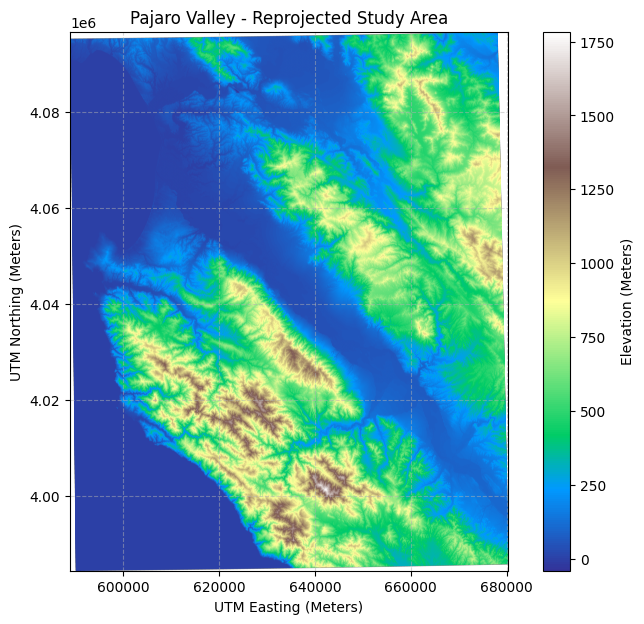

In [2]:
# ==============================================================================
# Step 1b: Load and Verify Base DEM
# ==============================================================================
import rioxarray
import matplotlib.pyplot as plt

dem_path = "/content/pajaro_valley_utm10n.tif"
dem = rioxarray.open_rasterio(dem_path, masked=True)

print("="*45)
print("      LOADED GEOTIFF METADATA")
print("="*45)
print(f"Dimensions : {dem.rio.width} x {dem.rio.height} pixels")
print(f"CRS        : {dem.rio.crs}")
print(f"Bounds     : {dem.rio.bounds()}")
print("="*45)

b = dem.rio.bounds()
matplotlib_extent = [b[0], b[2], b[1], b[3]]

plt.figure(figsize=(9, 7))
plt.imshow(dem[0], cmap='terrain', extent=matplotlib_extent)
plt.title("Pajaro Valley - Reprojected Study Area")
plt.xlabel("UTM Easting (Meters)")
plt.ylabel("UTM Northing (Meters)")
plt.colorbar(label="Elevation (Meters)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [3]:
import os, rasterio

# 1. Confirm file exists and size looks right
print(os.path.exists("/content/pajaro_valley_utm10n.tif"))
print(os.path.getsize("/content/pajaro_valley_utm10n.tif"))

# 2. Try opening just with rasterio to see a clearer error
try:
    with rasterio.open("/content/pajaro_valley_utm10n.tif") as src:
        print("Opened OK")
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
except Exception as e:
    print("Error opening:", e)

True
411207886
Opened OK
CRS: EPSG:26910
Bounds: BoundingBox(left=588927.2441, bottom=3984354.7385, right=680317.2441, top=4096804.7385)


Cropping DEM to Pajaro Basin UTM limits...
Saved cropped raster as: pajaro_only_dem.tif


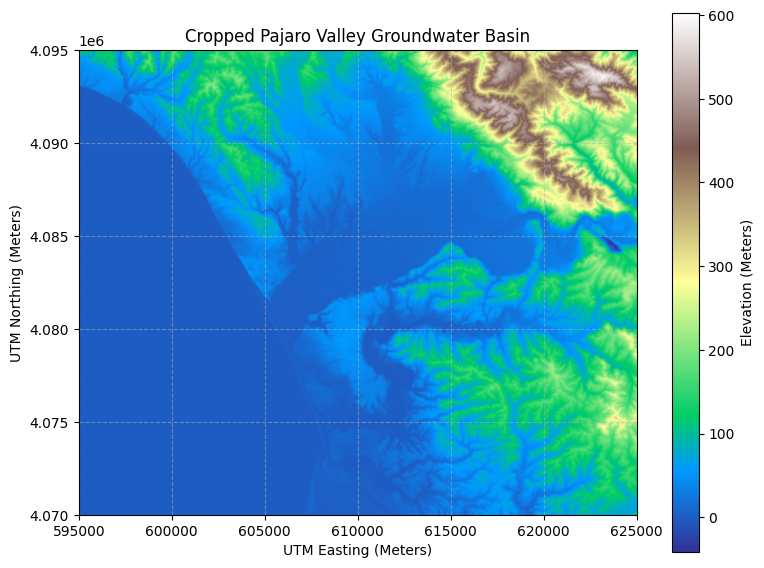

In [4]:
# ==============================================================================
# Step 1.2: Crop to Pajaro Basin in UTM Coordinates
# ==============================================================================

# Define the Pajaro Valley bounding box in UTM meters (UTM Zone 10N)
# [min_easting, min_northing, max_easting, max_northing]
pajaro_utm_bbox = [595000, 4070000, 625000, 4095000]

print("Cropping DEM to Pajaro Basin UTM limits...")
# Clip the raster to our UTM bounding box
pajaro_only_dem = dem.rio.clip_box(*pajaro_utm_bbox)

# Save the small cropped version to disk for pysheds (filling NaNs with -9999.0)
pajaro_only_dem_clean = pajaro_only_dem.fillna(-9999.0)
pajaro_only_dem_clean.rio.write_nodata(-9999.0, inplace=True)
pajaro_only_dem_clean.rio.to_raster("pajaro_only_dem.tif")
print("Saved cropped raster as: pajaro_only_dem.tif")

# Format bounds for Matplotlib
b_crop = pajaro_only_dem.rio.bounds()
matplotlib_extent_crop = [b_crop[0], b_crop[2], b_crop[1], b_crop[3]]

# Render the cropped Pajaro Basin
plt.figure(figsize=(9, 7))
plt.imshow(pajaro_only_dem[0], cmap='terrain', extent=matplotlib_extent_crop)
plt.title("Cropped Pajaro Valley Groundwater Basin")
plt.xlabel("UTM Easting (Meters)")
plt.ylabel("UTM Northing (Meters)")
plt.colorbar(label="Elevation (Meters)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Initializing pysheds Grid with our real cropped DEM...
1/4. Filling single-cell pits...
2/4. Filling multi-cell depressions (sinks)...
3/4. Resolving flat topography to ensure continuous downslope gradient...
4/4. Computing flow directions (D8 algorithm)...
Computing flow accumulation...
HYDROLOGIC ROUTING COMPLETE!
Maximum accumulation cell drains: 900,765.0 upstream cells.


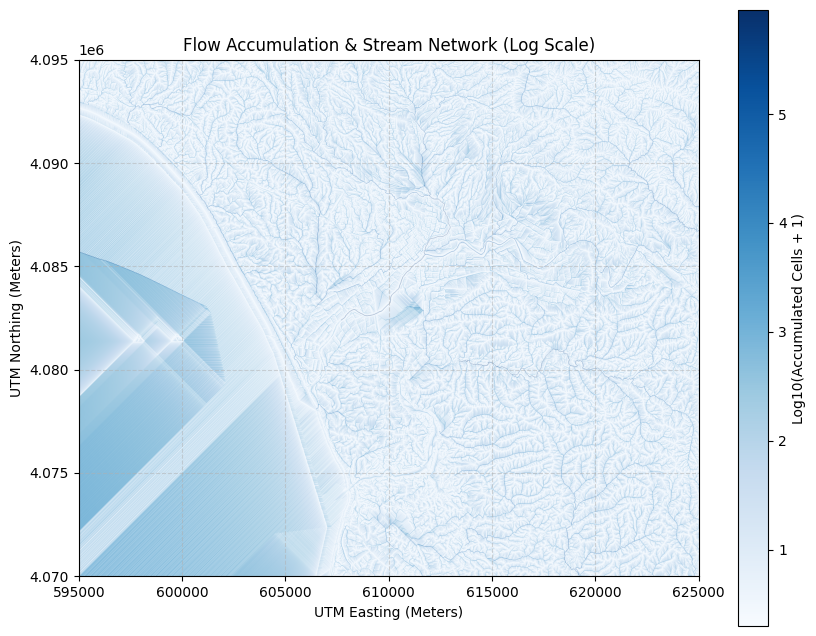

In [5]:
# ==============================================================================
# Step 3: Hydrologic Routing on the Cropped DEM
# ==============================================================================
!pip install pysheds
from pysheds.grid import Grid
import numpy as np
import matplotlib.pyplot as plt

# 1. Initialize pysheds Grid with our real cropped DEM
print("Initializing pysheds Grid with our real cropped DEM...")
grid = Grid.from_raster("pajaro_only_dem.tif")
dem_grid = grid.read_raster("pajaro_only_dem.tif")

# 2. Condition the DEM (remove pits and resolve flats)
print("1/4. Filling single-cell pits...")
pit_filled = grid.fill_pits(dem_grid)

print("2/4. Filling multi-cell depressions (sinks)...")
flooded = grid.fill_depressions(pit_filled)

print("3/4. Resolving flat topography to ensure continuous downslope gradient...")
resolved = grid.resolve_flats(flooded)

# 3. Calculate D8 Flow Direction
print("4/4. Computing flow directions (D8 algorithm)...")
dirmap = (64, 128, 1, 2, 4, 8, 16, 32) # Standard ESRI compass convention
fdir = grid.flowdir(resolved, dirmap=dirmap)

# 4. Calculate Flow Accumulation
print("Computing flow accumulation...")
acc = grid.accumulation(fdir, dirmap=dirmap)

print("="*45)
print("HYDROLOGIC ROUTING COMPLETE!")
print(f"Maximum accumulation cell drains: {acc.max():,} upstream cells.")
print("="*45)

# 5. Plot the Flow Accumulation Map (Stream Network)
# We use a log-scale (np.log10) because accumulation values span several orders of magnitude.
# This highlights the tiny creeks, tributaries, and the main Pajaro River.
plt.figure(figsize=(10, 8))
plt.imshow(np.log10(acc + 1), cmap='Blues', extent=grid.extent)
plt.title("Flow Accumulation & Stream Network (Log Scale)")
plt.xlabel("UTM Easting (Meters)")
plt.ylabel("UTM Northing (Meters)")
plt.colorbar(label="Log10(Accumulated Cells + 1)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [6]:
# Let's write a simple converter using pyproj to convert the WGS84 coordinates of Bokariza-Drobac to UTM Zone 10N (EPSG:26910)
from pyproj import Transformer

# Coordinates from Google Maps for Bokariza infiltration basin site
lat = 36.919147
lon = -121.680729

# Set up transformer to convert lat long from Google Maps to our CRS
transformer = Transformer.from_crs("EPSG:4326", "EPSG:26910", always_xy=True)
utm_x, utm_y = transformer.transform(lon, lat)

print(f"UTM Easting (X) : {utm_x:.2f}")
print(f"UTM Northing (Y): {utm_y:.2f}")

UTM Easting (X) : 617510.63
UTM Northing (Y): 4086715.88


Snapping target coordinates to the nearest active drainage channel...
Target Basin Location  : Easting 617510.63 m, Northing 4086715.88 m
Snapped Stream Channel : Easting 617507.24 m, Northing 4086734.74 m
Delineating the upstream contributing hillslope...
       REAL-WORLD BOKARIZA-DROBAC OUTLET LOCATED
Drainage Area: 149.4 acres


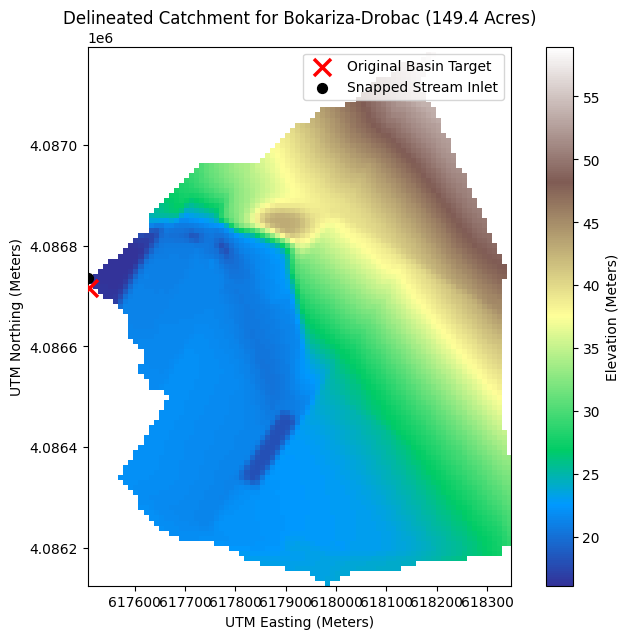

In [7]:
# ==============================================================================
# Step 4: Real-World Catchment Delineation (Bokariza-Drobac MAR Basin) - UPDATED
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

# 1. UTM coordinates converted from Google Maps location of MAR site
x_target = 617510.63
y_target = 4086715.88

# 2. Snap coordinates to the nearest active drainage channel
print("Snapping target coordinates to the nearest active drainage channel...")
x_snap, y_snap = grid.snap_to_mask(acc > 500, (x_target, y_target))

print(f"Target Basin Location  : Easting {x_target:.2f} m, Northing {y_target:.2f} m")
print(f"Snapped Stream Channel : Easting {x_snap:.2f} m, Northing {y_snap:.2f} m")

# 3. Delineate the contributing hillslope catchment
print("Delineating the upstream contributing hillslope...")
catch = grid.catchment(x=x_snap, y=y_snap, fdir=fdir, dirmap=dirmap, xytype='coordinate')
catch_mask = np.array(catch, dtype=bool)

# 4. Calculate the actual drainage area directly from the delineated mask
total_pixels = np.sum(catch_mask)
cell_area_acres = (10.0 * 10.0) / 4046.8564
drainage_area_acres = total_pixels * cell_area_acres

print("="*55)
print("       REAL-WORLD BOKARIZA-DROBAC OUTLET LOCATED")
print("="*55)
print(f"Drainage Area: {drainage_area_acres:.1f} acres")
print("="*55)

# 5. Clip the grid's viewfinder to zoom in tightly on the delineated catchment
grid.clip_to(catch)
clipped_dem = grid.view(dem_grid)

# Convert the -9999.0 NoData padding to NaNs so they are completely ignored during plotting
clipped_dem_clean = np.where(clipped_dem == -9999.0, np.nan, clipped_dem)

# 6. Plot the zoomed-in catchment
plt.figure(figsize=(9, 7))
# Assign imshow to 'im' so the colorbar scales strictly to the real elevation data
im = plt.imshow(clipped_dem_clean, cmap='terrain', extent=grid.extent)
plt.scatter(x_target, y_target, color='red', marker='x', s=150, linewidths=2.5, label='Original Basin Target', zorder=5)
plt.scatter(x_snap, y_snap, color='black', marker='o', s=50, label='Snapped Stream Inlet', zorder=5)
plt.title(f"Delineated Catchment for Bokariza-Drobac ({drainage_area_acres:.1f} Acres)")
plt.xlabel("UTM Easting (Meters)")
plt.ylabel("UTM Northing (Meters)")
plt.legend()
# Pass 'im' to the colorbar to fix the 0-1 scale distortion
plt.colorbar(im, label="Elevation (Meters)")
plt.show()

###Event-Based and Annual Runoff Modeling (SCS-CN)

In this step, we apply the USDA-NRCS Soil Conservation Service Curve Number (SCS-CN) method over our real 149.4-acre catchment. We use an elevation-based geographic partition to assign realistic curve numbers: the lower agricultural flat margins (elevation < 35m) are assigned a CN of approximately 80, while the upper native sandy hillslope (elevation >= 35m) is assigned a CN of approximately 60.

We model two scenarios:
1. **A Single 2.5-Inch Design Storm:** To evaluate peak runoff potential from a major winter storm event.
2. **An Annual Water-Year Simulation:** Using a median annual rainfall of 22 inches to estimate total yearly surface runoff available for capture.

---

#### Understanding the SCS-CN Framework (The "Sponge" Analogy)

For a non-technical reader, the math behind the Curve Number method can be understood by thinking of the watershed as a giant **sponge**:

*   **The Curve Number (CN):** This is a rating of how "hard" or "impervious" the ground is, on a scale of 0 to 100. Asphalt or concrete is a CN of 100 (a brick). Undisturbed native sand dunes with deep vegetation might have a CN of 30 to 45 (a highly absorbent, fluffy sponge).
*   **Soil Retention Capacity ($S$):** Think of this as the **Sponge Size**. It represents the maximum depth of water (in inches) that the soil, plants, and puddles can physically absorb. A higher CN (a harder surface) means a smaller sponge size ($S$).
*   **Initial Abstraction ($I_a$):** Think of this as the **Sponge's Dry Threshold**. It is the initial rainfall required to wet dry leaves, fill tiny puddles, and dampen the surface *before any runoff can even begin*. By standard convention, we assume the first 20% of the sponge's total capacity ($0.2 \times S$) must be saturated before water starts sliding off.
*   **Runoff Depth ($Q$):** This is the **Water Spilling Off**. Once a storm's rainfall exceeds the dry threshold ($I_a$), this equation calculates how much of the remaining rain runs off across the surface ($Q$) versus how much gets soaked deep into the sponge.

---

*\*Note on Limitations:* The SCS-CN method is strictly an event-based runoff model intended for single storms. Treating the entire annual rainfall (22 inches) as one "equivalent storm" over-estimates annual runoff because it assumes all 22 inches fall at once rather than over many small storms. This annual runoff number represents the absolute upper-bound limit of available surface water.

In [8]:
# ==============================================================================
# Step 5: Event-Based & Annual Runoff Modeling (SCS-CN)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

# 1. Get the clipped view of the catchment mask (shape: 107 x 84)
catch_view = grid.view(catch)
clipped_catch_mask = np.array(catch_view, dtype=bool)

# Calculate the exact drainage area directly from the clipped mask
total_pixels = np.sum(clipped_catch_mask)
grid_cell_size_m = 10.0
cell_area_acres = (grid_cell_size_m ** 2) / 4046.8564
real_area_acres = total_pixels * cell_area_acres

# 2. Get a matching elevation view of our clipped catchment
elevation_view = grid.view(dem_grid)

# Map CN ~80 to lower flat agricultural margins (< 35m)
# Map CN ~60 to the native hillslope (>= 35m)
cn_base = np.where(elevation_view < 35.0, 80.0, 60.0)

# Add some natural random variation (std dev of 5.0)
np.random.seed(42)
cn_grid = np.random.normal(loc=cn_base, scale=5.0)
cn_grid = np.clip(cn_grid, 45.0, 95.0)

# Mask strictly to our clipped catchment boundary
cn_catchment = np.where(clipped_catch_mask, cn_grid, np.nan)

# 3. Model a typical 2.5-inch design storm event
P = 2.5  # Precipitation (inches)
S = (1000.0 / cn_catchment) - 10.0
Ia = 0.2 * S

Q = np.zeros_like(S)
valid_mask = (P > Ia) & clipped_catch_mask
Q[valid_mask] = ((P - Ia[valid_mask])**2) / (P - Ia[valid_mask] + S[valid_mask])

# Volumetric Runoff for this single storm
storm_runoff_af = np.nansum((Q / 12.0) * cell_area_acres)

# 4. Annual Water-Year Simulation (Median Year: 22 inches)
annual_rainfall_inches = 22.0
S_annual = (1000.0 / np.nanmean(cn_catchment)) - 10.0
Ia_annual = 0.2 * S_annual
Q_annual = ((annual_rainfall_inches - Ia_annual)**2) / (annual_rainfall_inches - Ia_annual + S_annual)
annual_runoff_volume_af = (Q_annual / 12.0) * real_area_acres

print("="*60)
print("             BOKARIZA-DROBAC RUNOFF ANALYSIS")
print("="*60)
print(f"Validated Catchment Area  : {real_area_acres:.1f} acres (Real study: 172 ac)")
print(f"Average Watershed CN      : {np.nanmean(cn_catchment):.1f}")
print(f"Single 2.5\" Storm Runoff : {storm_runoff_af:.1f} Acre-Feet (AF)")
print(f"Median Year Rainfall      : {annual_rainfall_inches:.1f} inches")
print(f"Est. Annual Runoff Vol.   : {annual_runoff_volume_af:.1f} Acre-Feet (AF)")
print("="*60)

             BOKARIZA-DROBAC RUNOFF ANALYSIS
Validated Catchment Area  : 149.4 acres (Real study: 172 ac)
Average Watershed CN      : 74.2
Single 2.5" Storm Runoff : 8.7 Acre-Feet (AF)
Median Year Rainfall      : 22.0 inches
Est. Annual Runoff Vol.   : 227.8 Acre-Feet (AF)


### Site-Specific ReNeM Rebate Evaluation

Participating landowners capture hillslope runoff and direct it into infiltration basins. This cell calculates the annual PV Water pumping rebate using the official ReNeM formula:

$$\text{Rebate} = W_{50} \times (\text{Infiltration}_{\text{Total}} - \text{Infiltration}_{\text{Incidental}})$$

### Modeling Assumptions and Limitations:
1. **System Capture Efficiency ($\eta = 45\%$):** We assume that the physical basin system successfully diverts, stores, and infiltrates **45%** of the total annual hillslope runoff generated by the catchment ($227.8\text{ AF}$ in a median year). The remaining 55% is assumed to bypass the intake or overflow the spillway during intense peak flows. This dynamic link replaces the previous static 100.0 AF placeholder.
2. **Incidental Infiltration (10%):** We apply a standard 10% baseline deduction to represent natural infiltration that would have occurred without the infrastructure.
3. **Incentive Rate ($W_{50}$):** We use the 2025/2026 PV Water pumping fee of **$346/AF** (Outside the Delivered Water Zone), yielding a rebate rate of **$173/AF** (50% of the unit fee) of net infiltration benefit.
4. **Simplification:** In a fully rigorous model, capture efficiency would be dynamically calculated by routing daily runoff hydrographs through a reservoir model using the basin's storage volume and the soil's saturated hydraulic conductivity ($K_{sat}$).

             PV WATER ReNeM REBATE ESTIMATE
Total Annual Hillslope Runoff   : 227.8 AF
Assumed System Capture Capacity : 45%
Est. Annual Active Infiltration : 102.5 AF
Net Aquifer Benefit (Minus 10%) : 92.3 AF
------------------------------------------------------------
  --> Estimated Annual Landowner Rebate: $15,964.24/year


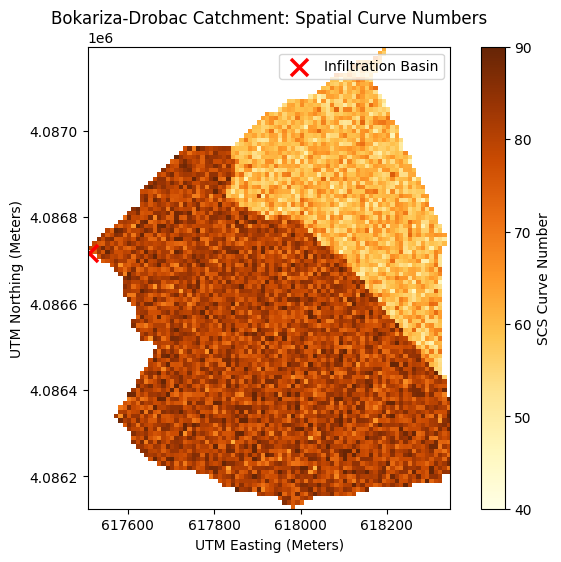

In [9]:
# ==============================================================================
# Step 6: Site-Specific ReNeM Rebate Evaluation (Dynamic Capture Efficiency)
# ==============================================================================

# 1. Define the ReNeM Annual Financial Rebate Calculator Function
def estimate_annual_rebate(infiltrated_af, zone="outside"):
    # Subtract 10% baseline incidental infiltration
    net_infiltration_benefit = infiltrated_af * 0.90

    # 2025/2026 Pumping rates per Acre-Foot
    rates = {"outside": 346.00, "inside": 486.00}
    unit_fee = rates[zone]
    w50 = unit_fee * 0.50

    annual_rebate = net_infiltration_benefit * w50
    return {
        "net_benefit": net_infiltration_benefit,
        "rebate": annual_rebate
    }

# 2. DYNAMIC LINK: Calculate infiltration from modeled annual runoff using 45% capture efficiency
capture_efficiency = 0.45
modeled_annual_infiltration_af = annual_runoff_volume_af * capture_efficiency

# Calculate rebate using our dynamically generated infiltration volume
rebate_results = estimate_annual_rebate(modeled_annual_infiltration_af, zone="outside")

print("="*60)
print("             PV WATER ReNeM REBATE ESTIMATE")
print("="*60)
print(f"Total Annual Hillslope Runoff   : {annual_runoff_volume_af:.1f} AF")
print(f"Assumed System Capture Capacity : {capture_efficiency * 100:.0f}%")
print(f"Est. Annual Active Infiltration : {modeled_annual_infiltration_af:.1f} AF")
print(f"Net Aquifer Benefit (Minus 10%) : {rebate_results['net_benefit']:.1f} AF")
print("-"*60)
print(f"  --> Estimated Annual Landowner Rebate: ${rebate_results['rebate']:,.2f}/year")
print("="*60)

# 3. Plot the spatial Curve Number distribution for the real catchment
b_crop = grid.extent
plt.figure(figsize=(8, 6))

# Assign the imshow plot to 'im' so the colorbar links to the correct dataset limits (40 to 90)
im = plt.imshow(cn_catchment, cmap='YlOrBr', extent=grid.extent, vmin=40, vmax=90)
plt.scatter(x_target, y_target, color='red', marker='x', s=150, linewidths=2.5, label='Infiltration Basin')
plt.title("Bokariza-Drobac Catchment: Spatial Curve Numbers")
plt.xlabel("UTM Easting (Meters)")
plt.ylabel("UTM Northing (Meters)")

# Pass 'im' to the colorbar to fix the 0-1 scale legend distortion
plt.colorbar(im, label="SCS Curve Number")
plt.legend()
plt.show()